# 00 — ตรวจคุณภาพและเตรียมข้อมูล

ตรวจข้อมูล curated ก่อนวิเคราะห์: โครงสร้าง วันซื้อขาย ค่าว่าง ราคา ผลตอบแทน และการคำนวณ RV รวมถึงตรวจวันสุดขั้วกับ raw snapshot

การเตรียมข้อมูลในเล่มนี้คือแปลงรูปแบบวันที่และเรียงข้อมูลในหน่วยความจำ ไม่มีการเติมวันซื้อขาย เดาราคา ตัดวันสุดขั้ว หรือเขียนทับ Parquet หากการตรวจหลักไม่ผ่าน ให้แก้ที่ pipeline ก่อนทำ EDA

## 0. Environment และไลบรารีที่ใช้

ติดตั้งจาก **โฟลเดอร์หลักของโปรเจกต์** ก่อนเปิด notebook:

```bash
uv sync --locked --no-dev --group eda
uv run --locked --no-dev --group eda jupyter lab
```

เลือก kernel ของ `.venv` ในโปรเจกต์ หากใช้ pip ให้ติดตั้ง `python -m pip install -r requirements.txt` ใน environment นั้นแทน
คำสั่งติดตั้งอยู่ใน Markdown เพื่อไม่เปลี่ยน environment ระหว่างวิเคราะห์ ไม่ใช้ `!pip install` ภายใน notebook
เซลล์ถัดไปรวม imports และแสดง Python/เวอร์ชันที่ใช้ หากขาดไลบรารีต้องติดตั้งให้ครบก่อนทำต่อ

In [1]:
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas_market_calendars as mcal
from IPython.display import Markdown, display

%matplotlib inline

print("Python:", sys.version.split()[0])
print("Kernel executable:", sys.executable)
display(pd.DataFrame(
    [(name, version(name)) for name in (
        "pandas", "numpy", "matplotlib", "pandas-market-calendars",
        "pyarrow", "PyYAML", "ipykernel", "jupyterlab",
    )], columns=["library", "version"]
))

Python: 3.10.21
Kernel executable: d:\New folder (2)\datasci-and-dataen-project\.venv\Scripts\python.exe


,library,version
0,pandas,2.2.3
1,numpy,2.2.6
2,matplotlib,3.10.9
3,pandas-market-calendars,5.5.0
4,pyarrow,25.0.1
5,PyYAML,6.0.3
6,ipykernel,6.31.0
7,jupyterlab,4.6.6


## 1. โหลดข้อมูลและกำหนดวันซื้อขาย

อ่าน config ปัจจุบันเพื่อกำหนดช่วงที่จะตรวจ ส่วนหลักฐานว่า ingestion ใช้อะไรจริงจะแสดงแยกในหัวข้อ 1.1 ไม่ถือว่าไฟล์ config ปัจจุบันคือ snapshot ของรอบเดิม

In [2]:
# รองรับการเปิด notebook จาก root, notebooks/ หรือโฟลเดอร์ย่อยในโปรเจกต์
project_root = next((
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "config" / "ingestion.yaml").is_file() and (path / "src").is_dir()
), None)
if project_root is None:
    raise FileNotFoundError("เปิด notebook ภายในโฟลเดอร์โปรเจกต์ที่มี config/ingestion.yaml")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ingestion.config import load_config
from src.eda.quality import inspect_market_prices, add_historical_rv, inspect_historical_rv

config = load_config(project_root / "config" / "ingestion.yaml")
data_path = project_root / "data" / "curated" / "market_prices_daily.parquet"
if not data_path.is_file():
    raise FileNotFoundError(f"ไม่พบ {data_path}; กรุณารัน ingestion pipeline ก่อน")
source_df = pd.read_parquet(data_path)
if source_df.empty:
    raise ValueError("ข้อมูล curated ว่าง; กรุณารัน ingestion pipeline ก่อน")

# หาวันเริ่ม warm-up จากปฏิทินตลาด แทนการเดาจากข้อมูลที่มีอยู่
calendar = mcal.get_calendar(config["calendar"]["market"])
start_date = pd.Timestamp(config["date_range"]["start_date"])
end_date = pd.Timestamp(config["date_range"]["end_date"])
warmup_days = config["date_range"]["warmup_trading_days"]
lookback_years = max(2, warmup_days // 150 + 2)
while True:
    prior_sessions = calendar.schedule(
        start_date=start_date - pd.DateOffset(years=lookback_years),
        end_date=start_date - pd.Timedelta(days=1),
    ).index
    if len(prior_sessions) >= warmup_days:
        break
    lookback_years *= 2
fetch_start = prior_sessions[-warmup_days]
expected_sessions = calendar.schedule(start_date=fetch_start, end_date=end_date).index

print(f"จำนวนแถว: {source_df.shape[0]:,} | จำนวนคอลัมน์: {source_df.shape[1]}")
print("ช่วงที่ควรมีข้อมูล:", fetch_start.date(), "ถึง", end_date.date())
print("จำนวนวันซื้อขายที่ควรมีต่อสินทรัพย์:", len(expected_sessions))
price_order = ['date', 'ticker', 'adjusted_close', 'open', 'high', 'low']
display_order = price_order + [column for column in source_df.columns if column not in price_order]
df = source_df.reindex(columns=display_order).copy()
display(df.head())

จำนวนแถว: 3,948 | จำนวนคอลัมน์: 13
ช่วงที่ควรมีข้อมูล: 2021-06-30 ถึง 2026-09-25
จำนวนวันซื้อขายที่ควรมีต่อสินทรัพย์: 1316


,date,ticker,adjusted_close,open,high,low,simple_return,log_return,is_anomaly_flagged,is_warmup_buffer,run_id,source_batch_id,ingested_at_utc
0,2021-06-30,GLD,165.630005,164.570007,166.100006,164.289993,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.340704+00:00
1,2021-06-30,IEF,98.787727,98.779178,98.933147,98.762067,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.334702+00:00
2,2021-06-30,SPY,399.087006,398.294532,399.758274,398.266563,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.328193+00:00
3,2021-07-01,GLD,166.199997,166.649994,166.880005,165.500000,0.003441,0.003435,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.340704+00:00
4,2021-07-01,IEF,98.716690,98.759484,98.819400,98.579735,-0.000719,-0.000719,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.334702+00:00


### 1.1 ข้อมูลชุดที่กำลังตรวจและหลักฐาน ingestion

ใช้ `run_id` และ `source_batch_id` จากแถวข้อมูลจริงเพื่อหา manifest ของ raw และ metadata ของ run ที่ตรงกัน แสดงเวลาเป็น UTC เพื่อให้ตรงกับหลักฐานต้นทาง SHA-256 ระบุไฟล์ curated ที่เปิดในครั้งนี้ และใช้ตรวจว่า raw ยังตรงกับ manifest

ตารางพารามิเตอร์เปรียบเทียบค่าที่บันทึกไว้กับ config ปัจจุบัน ส่วนวันที่จริงต้องอยู่ภายในขอบเขตที่ขอ `config_end_date` รวมวันปลายช่วง แต่ `api_end_date` เป็นขอบเขตแบบไม่รวมวันนั้น จึงตั้งเป็นวันถัดจาก `effective_end_date`

ถ้าหลักฐานที่มีขัดกันจะหยุดให้ตรวจต่อ หากไฟล์หลักฐานไม่อยู่จะแสดง **ไม่พบหลักฐาน** โดยไม่อ้างว่าผ่าน ข้อมูลยังตรวจคุณภาพเชิงตารางในหัวข้อ 3 ได้ แต่ยังยืนยันที่มาครบไม่ได้

**ข้อจำกัด:** metadata เดิมเก็บเฉพาะพารามิเตอร์สำคัญ ไม่ใช่ config snapshot เต็มชุด จึงยังยืนยันค่าตั้งต้นทุกตัวของรอบเดิมไม่ได้

**ประวัติชุดปัจจุบัน:** batch `yf_20261108_124004_bddf` ถูกเติมคอลัมน์ `open` ใน curated ภายหลังจาก `Open` ใน raw batch เดิม โดยไม่ได้เปลี่ยนคอลัมน์เดิมหรือเขียนทับ raw ดังนั้น manifest เดิมอธิบายการดึงข้อมูล ส่วน SHA-256 ของ curated ด้านล่างระบุไฟล์ฉบับที่กำลังตรวจ

In [3]:
import hashlib
import json

print('Curated:', data_path.relative_to(project_root))
print('Curated SHA-256:', hashlib.sha256(data_path.read_bytes()).hexdigest())
lineage_rows, parameter_rows = [], []
for run_id, batch_id in source_df[['run_id', 'source_batch_id']].drop_duplicates().itertuples(index=False, name=None):
    manifest_path = project_root / 'data' / 'raw' / str(batch_id) / 'manifest.json'
    metadata_path = project_root / 'data' / 'audit' / str(run_id) / 'run_metadata.json'
    manifest = json.loads(manifest_path.read_text(encoding='utf-8')) if manifest_path.is_file() else {}
    metadata = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.is_file() else {}
    lineage_rows.append({
        'run_id': run_id, 'source_batch_id': batch_id,
        'started_at_utc': metadata.get('started_at_utc', 'ไม่พบหลักฐาน'),
        'downloaded_at_utc': manifest.get('downloaded_at_utc', 'ไม่พบหลักฐาน'),
        'manifest': str(manifest_path.relative_to(project_root)) if manifest else 'ไม่พบหลักฐาน',
    })

    # ค่า None คือยังไม่มีหลักฐาน ห้ามแสดงเป็น PASS
    def compare(name, recorded, expected):
        status = 'ไม่พบหลักฐาน' if recorded is None else ('PASS' if recorded == expected else 'FAIL')
        parameter_rows.append({'source_batch_id': batch_id, 'check': name,
                               'recorded': recorded, 'expected': expected, 'status': status})

    compare('manifest.run_id', manifest.get('run_id'), run_id)
    compare('manifest.source_batch_id', manifest.get('source_batch_id'), batch_id)
    if metadata:
        compare('metadata.run_id', metadata.get('run_id'), run_id)
        compare('metadata.source_batch_id', metadata.get('source_batch_id'), batch_id)
    for key, expected in [
        ('requested_start_date', str(start_date.date())),
        ('requested_end_date', str(end_date.date())),
        ('actual_fetch_start_date', str(fetch_start.date())),
        ('auto_adjust', config['price']['auto_adjust']),
        ('interval', config['source']['interval']),
    ]:
        compare(key, manifest.get(key), expected)
    compare('tickers', sorted(manifest['tickers']) if 'tickers' in manifest else None,
            sorted(config['source']['tickers']))
    compare('canonical_price (current config)', config['price'].get('canonical_price'), 'adjusted_close')
    compare('auto_adjust required', manifest.get('auto_adjust'), True)

    # เทียบพารามิเตอร์ที่มีใน metadata กับ manifest ของรอบเดียวกัน
    if metadata and manifest:
        for meta_key, manifest_key in [('config_start_date', 'requested_start_date'),
                                       ('config_end_date', 'requested_end_date'),
                                       ('actual_fetch_start_date', 'actual_fetch_start_date'),
                                       ('effective_end_date', 'effective_end_date'),
                                       ('api_end_date', 'api_end_date'), ('auto_adjust', 'auto_adjust')]:
            compare(f'metadata.{meta_key}', metadata.get(meta_key), manifest.get(manifest_key))
    if manifest:
        raw_path = manifest_path.parent / 'raw_prices.csv'
        raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest() if raw_path.is_file() else None
        compare('raw SHA-256', raw_hash, manifest.get('sha256'))
        actual_dates = pd.to_datetime(source_df.loc[
            source_df.run_id.eq(run_id) & source_df.source_batch_id.eq(batch_id), 'date'
        ])
        first = pd.Timestamp(manifest['actual_fetch_start_date'])
        requested_end = pd.Timestamp(manifest['requested_end_date'])
        effective_end = pd.Timestamp(manifest['effective_end_date'])
        compare('actual_min_date >= fetch_start', bool(actual_dates.min() >= first), True)
        compare('actual_max_date <= effective_end_date', bool(actual_dates.max() <= effective_end), True)
        compare('effective_end_date <= config_end_date', bool(effective_end <= requested_end), True)
        compare('api_end_date (exclusive)', manifest.get('api_end_date'),
                str((effective_end + pd.Timedelta(days=1)).date()))

lineage_summary = pd.DataFrame(lineage_rows)
parameter_checks = pd.DataFrame(parameter_rows)
with pd.option_context('display.max_colwidth', None):
    display(lineage_summary)

# แสดงพารามิเตอร์หลักให้เห็นช่วงวันที่ โดยเก็บรายการตรวจย่อยไว้ในตัวแปร
main_checks = ['requested_start_date', 'requested_end_date', 'actual_fetch_start_date',
               'metadata.effective_end_date', 'api_end_date (exclusive)', 'auto_adjust', 'interval', 'tickers',
               'canonical_price (current config)']
display(parameter_checks.loc[parameter_checks.check.isin(main_checks)].reset_index(drop=True))
print('ผลตรวจหลักฐาน:', parameter_checks.status.value_counts().to_dict())
evidence_failures = parameter_checks.loc[parameter_checks.status.eq('FAIL')]
if not evidence_failures.empty:
    display(evidence_failures)
    raise ValueError('หลักฐาน ingestion หรือ config ขัดกับข้อมูลชุดที่กำลังตรวจ')
if parameter_checks.status.eq('ไม่พบหลักฐาน').any() or lineage_summary.started_at_utc.isna().any() or lineage_summary.started_at_utc.eq('\u0e44\u0e21\u0e48\u0e1e\u0e1a\u0e2b\u0e25\u0e31\u0e01\u0e10\u0e32\u0e19').any():
    print('ข้อจำกัด: หลักฐานบางส่วนไม่ครบ ยังยืนยันที่มาครบทุกข้อไม่ได้')
print('Canonical mapping: Close → adjusted_close; Open → open (auto_adjust=True ตาม contract)')

Curated: data\curated\market_prices_daily.parquet
Curated SHA-256: f08f3a180b9cf3a30c1c229f535245e32c51dec11cfcc81fb5bde0af1fe86736


,run_id,source_batch_id,started_at_utc,downloaded_at_utc,manifest
0,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08T12:40:04.244658+00:00,2026-11-08T12:40:05.319664+00:00,data\raw\yf_20261108_124004_bddf\manifest.json


,source_batch_id,check,recorded,expected,status
0,yf_20261108_124004_bddf,requested_start_date,2021-09-27,2021-09-27,PASS
1,yf_20261108_124004_bddf,requested_end_date,2026-09-25,2026-09-25,PASS
2,yf_20261108_124004_bddf,actual_fetch_start_date,2021-06-30,2021-06-30,PASS
3,yf_20261108_124004_bddf,auto_adjust,True,True,PASS
4,yf_20261108_124004_bddf,interval,1d,1d,PASS
5,yf_20261108_124004_bddf,tickers,"[GLD, IEF, SPY]","[GLD, IEF, SPY]",PASS
6,yf_20261108_124004_bddf,canonical_price (current config),adjusted_close,adjusted_close,PASS
7,yf_20261108_124004_bddf,metadata.effective_end_date,2026-09-25,2026-09-25,PASS
8,yf_20261108_124004_bddf,api_end_date (exclusive),2026-09-26,2026-09-26,PASS


ผลตรวจหลักฐาน: {'PASS': 23}
Canonical mapping: Close → adjusted_close; Open → open (auto_adjust=True ตาม contract)


## 2. บัญชีข้อมูลเริ่มต้นก่อนตรวจคุณภาพ

สรุปข้อมูล curated ที่อ่านเข้ามาก่อนการเตรียมรูปแบบ: จำนวนแถว ช่วงวันที่จริง warm-up และจำนวนคอลัมน์แยก ticker `memory_KiB` เป็นขนาดในหน่วยความจำโดยประมาณ (ไม่รวม index) ไม่ใช่ขนาดไฟล์บนดิสก์

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3948 entries, 0 to 3947
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   date                3948 non-null   object             
 1   ticker              3948 non-null   object             
 2   adjusted_close      3948 non-null   float64            
 3   open                3948 non-null   float64            
 4   high                3948 non-null   float64            
 5   low                 3948 non-null   float64            
 6   simple_return       3945 non-null   float64            
 7   log_return          3945 non-null   float64            
 8   is_anomaly_flagged  3948 non-null   bool               
 9   is_warmup_buffer    3948 non-null   bool               
 10  run_id              3948 non-null   object             
 11  source_batch_id     3948 non-null   object             
 12  ingested_at_utc     3948 non-null 

In [5]:
overview = df.groupby('ticker').agg(
    rows=('date', 'size'),
    actual_min_date=('date', 'min'),
    actual_max_date=('date', 'max'),
    warmup_rows=('is_warmup_buffer', 'sum'),
)
overview['analysis_rows'] = overview.rows - overview.warmup_rows
overview['columns'] = len(source_df.columns)
overview['memory_KiB'] = pd.Series({
    ticker: group.memory_usage(index=False, deep=True).sum() / 1024
    for ticker, group in df.groupby('ticker')
}).round(1)
display(overview)
print('คอลัมน์ที่อ่านเข้า:', ', '.join(display_order))
print(f'ขนาดไฟล์ curated บนดิสก์: {data_path.stat().st_size / 1024:,.1f} KiB')

,rows,actual_min_date,actual_max_date,warmup_rows,analysis_rows,columns,memory_KiB
ticker,,,,,,,
GLD,1316,2021-06-30,2026-09-25,61,1255,13,410.0
IEF,1316,2021-06-30,2026-09-25,61,1255,13,410.0
SPY,1316,2021-06-30,2026-09-25,61,1255,13,410.0


คอลัมน์ที่อ่านเข้า: date, ticker, adjusted_close, open, high, low, simple_return, log_return, is_anomaly_flagged, is_warmup_buffer, run_id, source_batch_id, ingested_at_utc
ขนาดไฟล์ curated บนดิสก์: 218.3 KiB


## 3. ตรวจคุณภาพและเตรียมรูปแบบข้อมูล

อ่านผลทีละเรื่องด้านล่าง: **0 หมายถึงไม่พบปัญหาในการตรวจนั้น** ส่วนค่าว่างของ return มีข้อยกเว้นที่อธิบายไว้ การตรวจละเอียดเดิมยังทำครบ แต่แสดงตารางปัญหาเฉพาะเมื่อไม่ผ่าน

ขั้นนี้แปลงรูปแบบวันที่และเรียงข้อมูลในหน่วยความจำ ไม่มีการเติมราคา ลบวันสุดขั้ว หรือเขียนทับไฟล์

In [6]:
df, quality_report = inspect_market_prices(source_df, config, expected_sessions)
df = df.reindex(columns=display_order)


### 3.1 Missing Values — ค่าว่าง

นับค่าว่างแยกทุกคอลัมน์ `simple_return` และ `log_return` ว่างได้เฉพาะแถวราคาแรกสุดของแต่ละสินทรัพย์ เพราะไม่มีราคาวันก่อนหน้า ส่วนคอลัมน์บังคับอื่นต้องไม่ว่าง

In [7]:
print('=== Missing Values ===')
print(source_df.reindex(columns=display_order).isna().sum().to_string())
print(f'หมายเหตุ: return แต่ละคอลัมน์ว่างได้ {len(config["source"]["tickers"])} ค่า หากอยู่ที่แถวแรกของแต่ละสินทรัพย์เท่านั้น')

=== Missing Values ===
date                  0
ticker                0
adjusted_close        0
open                  0
high                  0
low                   0
simple_return         3
log_return            3
is_anomaly_flagged    0
is_warmup_buffer      0
run_id                0
source_batch_id       0
ingested_at_utc       0
หมายเหตุ: return แต่ละคอลัมน์ว่างได้ 3 ค่า หากอยู่ที่แถวแรกของแต่ละสินทรัพย์เท่านั้น


### 3.2 Duplicate Records — แถวซ้ำ

หนึ่งสินทรัพย์ต้องมีหนึ่งแถวต่อวัน ตรวจด้วยคู่ `(date, ticker)` ตัวเลขนับทุกแถวที่อยู่ในกลุ่มซ้ำ เช่น มีข้อมูลคู่เดิมสองแถว จะนับเป็น 2 แถว

In [8]:
print('=== Duplicate Records ===')
print('จำนวนแถวที่มี date/ticker ซ้ำ:', int(quality_report.loc[quality_report.check.eq('duplicate_primary_key'), 'issues'].iloc[0]))

=== Duplicate Records ===
จำนวนแถวที่มี date/ticker ซ้ำ: 0


### 3.3 Trading Days — วันซื้อขาย

เทียบแต่ละสินทรัพย์กับปฏิทินตลาดตาม config รวม warm-up: `missing_days` คือวันซื้อขายที่ควรมีแต่ขาด และ `unexpected_days` คือวันที่เกินจากชุดที่ควรมี วันหยุดตลาดไม่ถือเป็นวันขาด

In [9]:
print('=== Trading Days ===')
session_checks = quality_report.loc[quality_report.check.isin(['missing_trading_sessions', 'unexpected_sessions'])]
session_summary = session_checks.pivot(index='ticker', columns='check', values='issues').rename(columns={
    'missing_trading_sessions': 'missing_days', 'unexpected_sessions': 'unexpected_days',
})
session_summary.columns.name = None
print(session_summary.to_string())

=== Trading Days ===
        missing_days  unexpected_days
ticker                               
GLD                0                0
IEF                0                0
SPY                0                0


### 3.4 Price Checks — ความถูกต้องของราคา

Open, Close, High และ Low ต้องเป็นตัวเลข finite (ไม่ใช่ NaN/Inf) และมากกว่า 0 ราคาเปิดและปิดต้องอยู่ระหว่าง Low–High โดยยอมให้คลาดเคลื่อน 0.0001 ทุกคอลัมน์ใช้ฐานปรับราคาเดียวกัน (`auto_adjust=True`)

แต่ละบรรทัดนับจำนวนแถวที่ผิดเงื่อนไขนั้น แถวเดียวอาจผิดหลายข้อ จึงไม่ควรบวกทุกบรรทัดเป็นจำนวนแถวเสีย

In [10]:
print('=== Price Checks ===')
price_names = {
    'positive_finite:adjusted_close': 'adjusted_close ไม่เป็น finite หรือไม่มากกว่า 0',
    'positive_finite:open': 'open ไม่เป็น finite หรือไม่มากกว่า 0',
    'positive_finite:high': 'high ไม่เป็น finite หรือไม่มากกว่า 0',
    'positive_finite:low': 'low ไม่เป็น finite หรือไม่มากกว่า 0',
    'high_low_consistency': 'ราคาเปิด/ปิดหรือช่วง Low–High ไม่สอดคล้อง',
}
price_summary = quality_report.set_index('check').loc[list(price_names), 'issues'].rename(index=price_names)
print(price_summary.to_string())

=== Price Checks ===
check
adjusted_close ไม่เป็น finite หรือไม่มากกว่า 0    0
open ไม่เป็น finite หรือไม่มากกว่า 0              0
high ไม่เป็น finite หรือไม่มากกว่า 0              0
low ไม่เป็น finite หรือไม่มากกว่า 0               0
ราคาเปิด/ปิดหรือช่วง Low–High ไม่สอดคล้อง         0


### 3.5 Return Checks — ความถูกต้องของผลตอบแทน

คำนวณ simple/log return ใหม่จากราคาปิดของสินทรัพย์เดียวกันที่เรียงตามวัน แล้วเทียบกับค่าที่เก็บไว้ (`rtol=1e-9`, `atol=1e-12`)

`invalid_values` คือจำนวนแถวที่ผิดเงื่อนไขค่าว่าง/finite ส่วน `formula_mismatches` คือจำนวนแถวที่ไม่ตรงสูตร แถวเดียวอาจถูกนับในทั้งสองคอลัมน์ได้

In [11]:
print('=== Return Checks ===')
return_checks = quality_report.loc[quality_report.check.str.match(r'^(simple_return|log_return):')].copy()
return_checks[['return_type', 'condition']] = return_checks.check.str.split(':', expand=True)
return_summary = return_checks.pivot(index=['ticker', 'return_type'], columns='condition', values='issues').rename(columns={
    'validity': 'invalid_values', 'formula': 'formula_mismatches',
})[['invalid_values', 'formula_mismatches']]
return_summary.columns.name = None
print(return_summary.to_string())

=== Return Checks ===
                      invalid_values  formula_mismatches
ticker return_type                                      
GLD    log_return                  0                   0
       simple_return               0                   0
IEF    log_return                  0                   0
       simple_return               0                   0
SPY    log_return                  0                   0
       simple_return               0                   0


### 3.6 Schema & Flags — โครงสร้างและตัวกำกับข้อมูล

สรุป `PASS` เมื่อการตรวจในหมวดนั้นผ่านครบ หรือ `FAIL` เมื่อมีอย่างน้อยหนึ่งข้อไม่ผ่าน:

- **ชนิดข้อมูล:** ราคาและ return เป็นตัวเลข, flags เป็น Boolean และเวลา ingestion เป็น UTC
- **วันที่และ ticker:** วันที่ถูกต้องและ ticker อยู่ในรายชื่อที่กำหนด
- **ข้อมูลบังคับ:** คอลัมน์ที่ต้องมีค่าและรหัสอ้างอิงไม่ว่าง
- **Flags:** warm-up ตรงกับวันก่อนเริ่มศึกษา และ anomaly flag ตรงกับเกณฑ์ใน config

หากพบ `FAIL` จะแสดงตารางรายละเอียดและหยุดก่อนวิเคราะห์ต่อ `issues` นับแถวที่ผิด ยกเว้นชนิดข้อมูลนับคอลัมน์ และวันซื้อขายนับวัน

`examples` คือ **ตัวอย่างปัญหา** ไม่ใช่ตัวอย่างข้อมูลทั่วไป: `['open']` หมายถึงคอลัมน์ที่มีปัญหา, `['2024-01-03']` หมายถึงวันที่มีปัญหา และ `[{'date': '...', 'ticker': '...'}]` หมายถึงตัวอย่างแถว โดยแสดงไม่เกิน 5 รายการต่อข้อ การตรวจที่ผ่านใช้ `—` ในรายงานละเอียด

In [12]:
print('=== Schema & Flags ===')
schema_groups = {
    'ชนิดข้อมูล': ['numeric_dtypes', 'boolean_dtypes', 'ingestion_timestamp_utc_dtype'],
    'วันที่และ ticker': ['valid_session_date', 'ticker_domain'],
    'ข้อมูลบังคับ': quality_report.loc[quality_report.check.str.startswith(('required_non_null:', 'nonempty_string:')), 'check'].tolist(),
    'Flags': ['warmup_flag_matches_config', 'anomaly_flag_matches_threshold'],
}
schema_status = pd.Series({
    label: 'PASS' if quality_report.loc[quality_report.check.isin(checks), 'status'].eq('PASS').all() else 'FAIL'
    for label, checks in schema_groups.items()
})
print(schema_status.to_string())

failures = quality_report.loc[quality_report.status.eq('FAIL')]
if not failures.empty:
    print('รายละเอียดปัญหา: ตรวจ issues และ examples ก่อนแก้ที่ต้นทาง')
    with pd.option_context('display.max_colwidth', None):
        display(failures)
    raise ValueError('ตรวจคุณภาพไม่ผ่าน; แก้ปัญหาก่อนวิเคราะห์ต่อ')

analysis = df.loc[~df.is_warmup_buffer].copy()
if analysis.empty:
    raise ValueError('ไม่มีข้อมูลในช่วงวิเคราะห์')
print(f'\nผ่านการตรวจครบ {len(quality_report)} รายการ')
print('จำนวนแถวในช่วงวิเคราะห์:', analysis.groupby('ticker').size().to_dict())
print('Anomaly flags ที่ต้องทบทวน:', int(df.is_anomaly_flagged.sum()), '(เป็นคำเตือน ไม่ใช่หลักฐานว่าข้อมูลผิด)')

=== Schema & Flags ===
ชนิดข้อมูล          PASS
วันที่และ ticker    PASS
ข้อมูลบังคับ        PASS
Flags               PASS

ผ่านการตรวจครบ 40 รายการ
จำนวนแถวในช่วงวิเคราะห์: {'GLD': 1255, 'IEF': 1255, 'SPY': 1255}
Anomaly flags ที่ต้องทบทวน: 0 (เป็นคำเตือน ไม่ใช่หลักฐานว่าข้อมูลผิด)


## 4. ตรวจสูตร RV และความพร้อมของ warm-up

คำนวณจากข้อมูลรวม warm-up โดยใช้เฉพาะผลตอบแทนย้อนหลังถึงวัน t ตาม feature contract:
`RV(n,t) = sqrt(252/n × sum(r²))` เป็น annualized decimal แบบไม่หักค่าเฉลี่ย

ตรวจอิสระด้วย NumPy dot product ของแต่ละหน้าต่างย้อนหลัง (ไม่ใช้ pandas rolling ในตัวตรวจ) รวมตำแหน่ง warm-up null และกำหนดให้ RV ทุกช่วง 5/20/60 วันในช่วงวิเคราะห์ต้อง finite และไม่ติดลบ
หากไม่ผ่านจะหยุดก่อนสรุปผล

In [13]:
df = add_historical_rv(df)
rv_checks = inspect_historical_rv(df)
display(rv_checks)
if rv_checks.status.eq("FAIL").any():
    raise ValueError("RV formula/readiness checks failed; ตรวจ example_dates ก่อนทำต่อ")
analysis = df.loc[~df.is_warmup_buffer].copy()

,ticker,window,formula_mismatches,invalid_analysis_rows,max_abs_error,status,example_dates
0,GLD,5,0,0,1.110223e-16,PASS,[]
1,GLD,20,0,0,1.110223e-16,PASS,[]
2,GLD,60,0,0,1.110223e-16,PASS,[]
3,IEF,5,0,0,1.283695e-16,PASS,[]
4,IEF,20,0,0,2.775558e-17,PASS,[]
5,IEF,60,0,0,2.775558e-17,PASS,[]
6,SPY,5,0,0,1.207368e-15,PASS,[]
7,SPY,20,0,0,1.110223e-16,PASS,[]
8,SPY,60,0,0,5.551115e-17,PASS,[]


## 5. เลือกวันสุดขั้วสำหรับตรวจสอบ
เลือก 5 วันตามขนาดสัมบูรณ์ของ simple return ภายในแต่ละ ticker จากช่วง analysis เพื่อใช้ตรวจสอบ ไม่ได้หมายความว่าข้อมูลผิด ราคาในวันก่อนหน้าใช้ลำดับการซื้อขายของ ticker เดียวกัน และแสดงค่าสูงสุด/ต่ำสุดแยกด้วย


In [14]:
review_data = df.sort_values(['ticker', 'date']).copy()
review_data['previous_close'] = review_data.groupby('ticker').adjusted_close.shift()
review_data['simple_return_pct'] = review_data.simple_return * 100
review_analysis = review_data.loc[~review_data.is_warmup_buffer & review_data.simple_return.notna()].copy()
review_analysis['magnitude'] = review_analysis.simple_return.abs()
events = review_analysis.sort_values(['ticker', 'magnitude', 'date'], ascending=[True, False, True]).groupby('ticker', sort=True).head(5).copy()
events['rank'] = events.groupby('ticker').cumcount() + 1
cols = ['ticker','rank','date','adjusted_close','open','previous_close','simple_return_pct','log_return','is_anomaly_flagged']
display(events[cols].reset_index(drop=True))
print('ค่าสูงสุดและต่ำสุดรายสินทรัพย์ (simple return)')
display(review_analysis.sort_values(['ticker','simple_return','date']).groupby('ticker').apply(lambda g: g.iloc[[0,-1]].drop_duplicates(), include_groups=False)[['date','simple_return_pct','log_return']])


,ticker,rank,date,adjusted_close,open,previous_close,simple_return_pct,log_return,is_anomaly_flagged
0,GLD,1,2026-01-30,444.950012,466.250000,495.899994,-10.274245,-0.108412,False
1,GLD,2,2025-10-21,377.239990,386.540009,403.149994,-6.426889,-0.066427,False
2,GLD,3,2026-02-03,454.290009,452.630005,427.130005,6.358721,0.061647,False
3,GLD,4,2026-03-03,468.140015,472.829987,490.000000,-4.461222,-0.045638,False
4,GLD,5,2025-12-29,398.600006,403.660004,416.739990,-4.352830,-0.044504,False
5,IEF,1,2022-09-28,84.004517,83.318162,82.153961,2.252546,0.022276,False
6,IEF,2,2022-11-10,83.870049,83.250664,82.029366,2.243932,0.022191,False
7,IEF,3,2023-03-10,85.600601,85.143264,84.052696,1.841589,0.018248,False
8,IEF,4,2022-06-13,85.526993,86.149386,87.074310,-1.777008,-0.017930,False
9,IEF,5,2022-09-26,82.718666,83.656974,84.117462,-1.662908,-0.016769,False


ค่าสูงสุดและต่ำสุดรายสินทรัพย์ (simple return)


date  simple_return_pct  log_return
ticker                                               
GLD    1151 2026-01-30         -10.274245   -0.108412
       1153 2026-02-03           6.358721    0.061647
IEF    1556 2022-06-13          -1.777008   -0.017930
       1630 2022-09-28           2.252546    0.022276
SPY    3577 2025-04-04          -5.854304   -0.060327
       3580 2025-04-09          10.501934    0.099863

## 6. ดูบริบทก่อนและหลังวันสุดขั้ว
ตรวจอันดับหนึ่งของแต่ละ ticker และ GLD 2026-01-30 หากมี โดยแสดงข้อมูลสูงสุด 5 วันซื้อขายก่อนและหลัง หากอยู่ใกล้ขอบจะแสดงเท่าที่มี


GLD 2026-01-30: ก่อน 5 วัน หลัง 5 วัน


,date,adjusted_close,open,high,low,simple_return_pct,log_return,is_anomaly_flagged
1146,2026-01-23,458.000000,454.109985,458.750000,453.450012,1.374530,0.013652,False
1147,2026-01-26,464.700012,466.779999,469.279999,460.359985,1.462885,0.014523,False
1148,2026-01-27,476.100006,465.070007,476.489990,463.950012,2.453194,0.024236,False
1149,2026-01-28,494.559998,483.390015,495.880005,481.250000,3.877335,0.038041,False
1150,2026-01-29,495.899994,509.510010,509.700012,468.510010,0.270947,0.002706,False
1151,2026-01-30,444.950012,466.250000,470.059998,430.799988,-10.274245,-0.108412,False
1152,2026-02-02,427.130005,434.010010,440.779999,422.549988,-4.004946,-0.040874,False
1153,2026-02-03,454.290009,452.630005,459.000000,448.309998,6.358721,0.061647,False
1154,2026-02-04,453.970001,462.470001,463.100006,445.709991,-0.070441,-0.000705,False
1155,2026-02-05,441.880005,444.290009,450.899994,440.350006,-2.663171,-0.026993,False


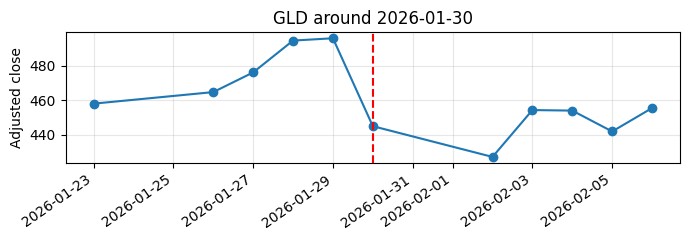

IEF 2022-09-28: ก่อน 5 วัน หลัง 5 วัน


,date,adjusted_close,open,high,low,simple_return_pct,log_return,is_anomaly_flagged
309,2022-09-21,85.299019,85.107881,85.385898,84.534475,0.398800,0.003980,False
310,2022-09-22,84.013229,84.412884,84.465011,83.917661,-1.507391,-0.015189,False
311,2022-09-23,84.117462,83.978457,84.247784,83.648308,0.124067,0.001240,False
312,2022-09-26,82.718666,83.656974,83.665664,82.597034,-1.662908,-0.016769,False
313,2022-09-27,82.153961,82.744747,82.840316,82.110525,-0.682681,-0.006850,False
314,2022-09-28,84.004517,83.318162,84.100085,82.988013,2.252546,0.022276,False
315,2022-09-29,83.613533,83.387649,83.908929,83.309454,-0.465432,-0.004665,False
316,2022-09-30,83.396355,83.978457,84.169588,83.109655,-0.259741,-0.002601,False
317,2022-10-03,84.386154,84.194643,85.004208,83.994426,1.186862,0.011799,False
318,2022-10-04,84.560219,84.725616,85.047696,84.403529,0.206272,0.002061,False


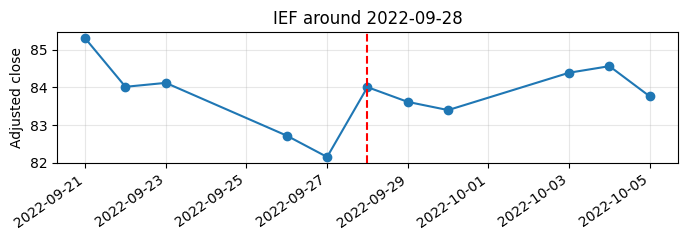

SPY 2025-04-09: ก่อน 5 วัน หลัง 5 วัน


,date,adjusted_close,open,high,low,simple_return_pct,log_return,is_anomaly_flagged
943,2025-04-02,555.308838,545.993327,558.161483,545.757253,0.632842,0.006308,False
944,2025-04-03,527.942810,536.215560,539.028879,527.942810,-4.928074,-0.050536,False
945,2025-04-04,497.035431,515.125349,517.289464,496.819019,-5.854304,-0.060327,False
946,2025-04-07,496.150146,481.207996,514.633533,473.938563,-0.178113,-0.001783,False
947,2025-04-08,488.379028,513.344882,516.413968,481.178460,-1.566284,-0.015787,False
948,2025-04-09,539.668274,485.388642,539.668274,485.004991,10.501934,0.099863,False
949,2025-04-10,516.020569,523.486691,524.795007,501.009553,-4.381896,-0.044808,False
950,2025-04-11,525.227783,514.476134,527.677145,511.584103,1.784273,0.017685,False
951,2025-04-14,530.323303,535.172854,535.399142,525.149120,0.970154,0.009655,False
952,2025-04-15,528.837891,530.864276,534.366185,528.050956,-0.280096,-0.002805,False


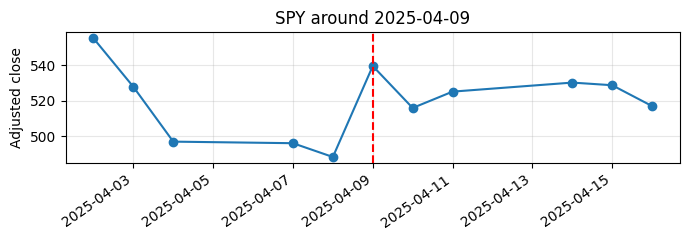

In [15]:
selected = events.loc[events['rank'].eq(1), ['ticker','date']].copy()
special = review_analysis.loc[review_analysis.ticker.eq('GLD') & review_analysis.date.eq(pd.Timestamp('2026-01-30')), ['ticker','date']]
selected = pd.concat([selected, special]).drop_duplicates().sort_values(['ticker','date'])
for event in selected.itertuples(index=False):
    group = review_data.loc[review_data.ticker.eq(event.ticker)].reset_index(drop=True)
    position = group.index[group.date.eq(event.date)][0]
    before, after = min(5, position), min(5, len(group)-position-1)
    print(f'{event.ticker} {event.date:%Y-%m-%d}: ก่อน {before} วัน หลัง {after} วัน')
    display(group.iloc[position-before:position+after+1][['date','adjusted_close','open','high','low','simple_return_pct','log_return','is_anomaly_flagged']])
    fig, ax = plt.subplots(figsize=(7, 2.5))
    window = group.iloc[position-before:position+after+1]
    ax.plot(window.date, window.adjusted_close, marker='o'); ax.axvline(event.date, color='red', linestyle='--')
    ax.set_title(f'{event.ticker} around {event.date:%Y-%m-%d}'); ax.set_ylabel('Adjusted close'); ax.grid(alpha=.3)
    fig.autofmt_xdate(rotation=35); plt.tight_layout(); plt.show()


## 7. หลักฐาน: raw snapshot และแหล่งภายนอก

ตรวจ **34 วันที่มีขนาด simple return สูงที่สุดของแต่ละ ticker รวม 102 แถวในข้อมูลปัจจุบัน** จากช่วง analysis หากข้อมูลมีน้อยกว่า 34 วันจะใช้เท่าที่มี เป็นการขยายรายการตรวจจากเหตุการณ์อันดับหนึ่ง โดยไม่เพิ่มจำนวน ticker และไม่เพิ่มกราฟบริบทตามจำนวนแถว

เทียบกับ snapshot เฉพาะ batch ที่ระบุใน curated และตรวจ manifest ว่า auto_adjust=True ก่อนเปรียบเทียบ Open, Close และ return ที่คำนวณจากวันซื้อขายก่อนหน้า ตารางเรียงตาม ticker และวันที่ แสดงทุกแถวโดยไม่ย่อกลางตาราง

หากไม่พบไฟล์จะแสดงข้อจำกัดโดยไม่หยุด notebook การตรงกันยืนยันเพียงความสอดคล้องภายใน Yahoo ชุดเดียวกัน ไม่ใช่การยืนยันจากแหล่งอิสระ ข้อมูลที่เลือกเน้นวันที่เคลื่อนไหวแรง จึงไม่ใช่ตัวอย่างสุ่มสำหรับสรุปคุณภาพข้อมูลทั้งหมด

In [16]:
import json
from src.eda.quality import raw_price_returns
# ขยายการตรวจเป็น 34 วันต่อ ticker โดยคงเหตุการณ์อันดับหนึ่งรวมอยู่ด้วย
raw_review_events = (
    review_analysis.sort_values(['ticker', 'magnitude', 'date'], ascending=[True, False, True])
    .groupby('ticker', sort=True).head(34)[['ticker', 'date']]
    .sort_values(['ticker', 'date']).reset_index(drop=True)
)
raw_results = []
for event in raw_review_events.itertuples(index=False):
    group = review_data.loc[review_data.ticker.eq(event.ticker)].reset_index(drop=True)
    pos = group.index[group.date.eq(event.date)][0]
    row = group.iloc[pos]
    result = {'ticker': event.ticker, 'date': event.date, 'status': 'ยังยืนยันไม่ได้: ไม่พบ raw ที่เชื่อมได้'}
    if pos > 0 and row.source_batch_id == group.iloc[pos-1].source_batch_id:
        folder = project_root / 'data' / 'raw' / str(row.source_batch_id)
        manifest_path, raw_path = folder / 'manifest.json', folder / 'raw_prices.csv'
        if manifest_path.is_file() and raw_path.is_file():
            try:
                manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
                raw = pd.read_csv(raw_path, parse_dates=['date'])
                subset = raw.loc[raw.ticker.eq(event.ticker) & raw.date.isin([event.date, group.iloc[pos-1].date])].set_index('date')
                if manifest.get('source_batch_id') == row.source_batch_id and manifest.get('auto_adjust') is True and len(subset) == 2 and subset.index.is_unique:
                    raw_open = float(subset.loc[event.date, 'Open'])
                    current = float(subset.loc[event.date, 'Close'])
                    previous = float(subset.loc[group.iloc[pos-1].date, 'Close'])
                    returns = raw_price_returns(previous, current)
                    if returns is None:
                        result['status'] = 'ยังยืนยันไม่ได้: ราคา raw ไม่ผ่านเงื่อนไข'
                    else:
                        raw_simple, raw_log = returns
                        result.update({'raw_file': str(raw_path.relative_to(project_root)), 'open': row.open, 'raw_open': raw_open, 'raw_close': current, 'raw_previous_close': previous,
                                       'raw_simple_return': raw_simple, 'raw_log_return': raw_log})
                        matches = np.allclose([raw_open, current, previous, raw_simple, raw_log], [row.open, row.adjusted_close, row.previous_close, row.simple_return, row.log_return], rtol=1e-9, atol=1e-12)
                        result['status'] = 'สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ' if matches else 'ไม่สอดคล้อง: ตรวจต่อ' 
                else:
                    result['status'] = 'ยังยืนยันไม่ได้: batch, adjustment หรือแถว raw ไม่ครบ'
            except (OSError, ValueError, KeyError, TypeError) as exc:
                result['status'] = f'ยังยืนยันไม่ได้: อ่าน raw ไม่สำเร็จ ({exc})'
    raw_results.append(result)
raw_evidence = pd.DataFrame(raw_results)
evidence_order = ['ticker', 'date', 'raw_close', 'open', 'raw_open', 'raw_previous_close',
                  'raw_simple_return', 'raw_log_return', 'raw_file', 'status']
raw_evidence = raw_evidence.reindex(columns=evidence_order)
print(f'ตรวจ raw snapshot {len(raw_evidence)} แถว: {raw_evidence.groupby("ticker").size().to_dict()}')
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', None):
    display(raw_evidence)


ตรวจ raw snapshot 102 แถว: {'GLD': 34, 'IEF': 34, 'SPY': 34}


,ticker,date,raw_close,open,raw_open,raw_previous_close,raw_simple_return,raw_log_return,raw_file,status
0,GLD,2022-11-04,156.470001,154.949997,154.949997,151.809998,0.030696,0.030235,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
1,GLD,2022-11-10,163.479996,162.009995,162.009995,158.649994,0.030444,0.029990,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
2,GLD,2023-10-13,178.830002,176.889999,176.889999,173.259995,0.032148,0.031642,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
3,GLD,2024-06-07,211.600006,215.070007,215.070007,219.429993,-0.035683,-0.036336,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
4,GLD,2024-11-06,245.699997,245.639999,245.639999,253.399994,-0.030387,-0.030858,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
5,GLD,2025-04-09,285.380005,282.220001,282.220001,275.200012,0.036991,0.036323,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
6,GLD,2025-04-16,307.470001,304.649994,304.649994,297.779999,0.032541,0.032023,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
7,GLD,2025-04-21,315.589996,315.019989,315.019989,306.119995,0.030936,0.030467,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
8,GLD,2025-10-20,403.149994,397.450012,397.450012,388.989990,0.036402,0.035755,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ
9,GLD,2025-10-21,377.239990,386.540009,386.540009,403.149994,-0.064269,-0.066427,data\raw\yf_20261108_124004_bddf\raw_prices.csv,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ


### ข้อสรุปและข้อจำกัด
- **GLD 2026-01-30:** [Dow Jones ผ่าน Tiger Brokers](https://www.itiger.com/news/2607024866) เผยแพร่ 30 มกราคม 2026 เวลา 16:35 ET รายงานราคาปิด 444.95 ดอลลาร์และลดลง 10.3% ในวันนั้น สนับสนุนทิศทางและขนาดโดยประมาณ แต่ไม่ยืนยัน adjusted return ทุกหลัก หรือวิธีปรับราคาย้อนหลัง
- **เหตุการณ์อันดับหนึ่งของ SPY และ IEF:** ตรวจความสอดคล้องกับ raw ตามตารางข้างต้น ยังไม่ได้ยืนยันจากแหล่งอิสระ
- หาก raw ขาดหรือไม่ตรง ให้ตรวจต่อโดยไม่ใช้ snapshot คนละ batch ทดแทนโดยอัตโนมัติ; คงค่าต้นฉบับไว้ระหว่างตรวจ การคงค่าไม่ใช่การรับรองว่าถูกต้อง
- เกณฑ์ flag คือ `abs(simple_return) > 0.20`; การไม่ติด flag ไม่ยืนยันความถูกต้อง และการติด flag ไม่พิสูจน์ว่าข้อมูลผิด


## 8. ขอบเขตการส่งต่อไป EDA

เมื่อการตรวจหลักผ่าน ใช้ข้อมูล curated ชุดเดิมใน `01_eda_market_prices.ipynb` ได้โดยตรง ไม่ต้องรันสองเล่มต่อกันใน kernel เดียว วันสุดขั้วยังคงอยู่ในข้อมูลหลัก และความสอดคล้องกับ raw ยืนยันเพียงความตรงกันกับ snapshot ของแหล่งเดิม ไม่ใช่การยืนยันจากแหล่งอิสระ